### **1: Install the required libraries**

In [1]:
!pip install -q tensorflow-model-optimization tf_keras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.7/242.7 kB 5.3 MB/s eta 0:00:00


### **2: Import libraries**

In [2]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import time
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_model_optimization as tfmot

from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)
print("TFMOT version:", tfmot.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
TFMOT version: 0.8.1
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### **3: Load and prepare CIFAR-10**

In [3]:
# Load CIFAR-10
(x_train_all, y_train_all), (x_test_all, y_test_all) = (
    tf.keras.datasets.cifar10.load_data()
)

# Convert labels from shape (N, 1) to (N,)
y_train_all = y_train_all.squeeze()
y_test_all = y_test_all.squeeze()

# Use a subset as specified in the lab
x_subset = x_train_all[:5000]
y_subset = y_train_all[:5000]

x_test = x_test_all[:1000]
y_test = y_test_all[:1000]

# Split 5000 images into training and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_subset,
    y_subset,
    test_size=0.10,
    random_state=42,
    stratify=y_subset
)

print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Test images:", x_test.shape)
print("Number of classes:", len(np.unique(y_subset)))

170498071/170498071 [==============================] - 1817s 11us/step
Training images: (4500, 32, 32, 3)
Validation images: (500, 32, 32, 3)
Test images: (1000, 32, 32, 3)
Number of classes: 10


#### ***Interpretation:***

We use 4,500 images for training, 500 for validation, and 1,000 separate images for testing. Validation data helps monitor training, while test data is reserved for the final comparison.

### **4: View sample images**

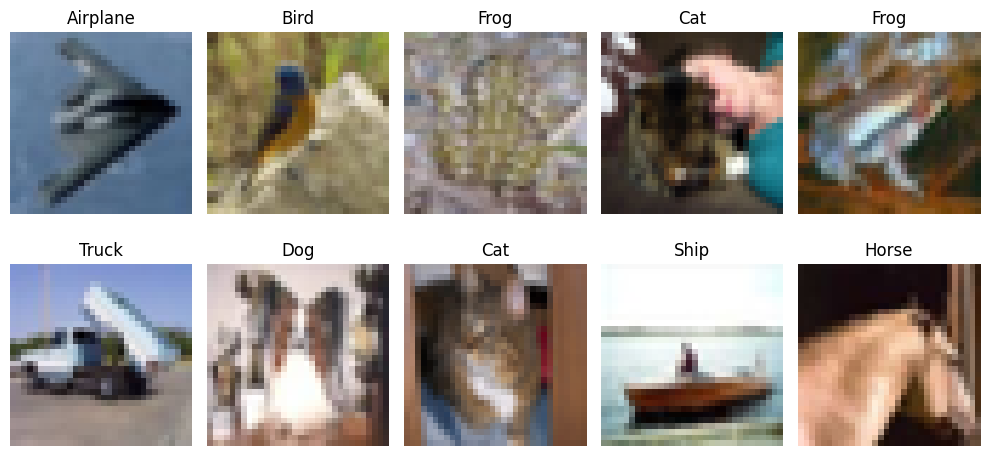

In [4]:
import matplotlib.pyplot as plt

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

### **5: Preprocess the images**

In [5]:
IMG_SIZE = 96
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    # Convert pixel values from [0, 255] to approximately [-1, 1]
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label


def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))

    ds = ds.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        ds = ds.shuffle(2000, seed=42)

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(x_train, y_train, training=True)
val_ds = make_dataset(x_val, y_val)
test_ds = make_dataset(x_test, y_test)

# Verify the processed image shape and value range
sample_images, sample_labels = next(iter(train_ds))

print("Batch shape:", sample_images.shape)
print("Minimum pixel value:", float(tf.reduce_min(sample_images)))
print("Maximum pixel value:", float(tf.reduce_max(sample_images)))
print("Labels shape:", sample_labels.shape)

Batch shape: (32, 96, 96, 3)
Minimum pixel value: -1.0
Maximum pixel value: 1.0
Labels shape: (32,)


### **6: Build the baseline MobileNetV2 model**

In [6]:
# Load the pretrained feature extractor
backbone = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    alpha=0.35,
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers for initial training
backbone.trainable = False

# Attach the classification head to the backbone's existing graph
x = tf.keras.layers.GlobalAveragePooling2D()(backbone.output)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(
    10,
    activation="softmax",
    name="cifar10_predictions"
)(x)

# One Functional model, rather than a nested backbone model
baseline_model = tf.keras.Model(
    inputs=backbone.input,
    outputs=outputs,
    name="mobilenetv2_cifar10"
)

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

2019640/2019640 [==============================] - 1s 1us/step
Model: "mobilenetv2_cifar10"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 96, 96, 3)]          0         []                            
                                                                                                  
 Conv1 (Conv2D)              (None, 48, 48, 16)           432       ['input_1[0][0]']             
                                                                                                  
 bn_Conv1 (BatchNormalizati  (None, 48, 48, 16)           64        ['Conv1[0][0]']               
 on)                                                                                              
                                                                                                  
 Conv1_relu (ReLU

#### ***Interpretation:***

- alpha=0.35 selects a narrower MobileNetV2 architecture to reduce computation.

- include_top=False removes the original ImageNet classifier.

- The new dense layer produces 10 class probabilities for CIFAR-10.

- The pretrained feature extractor is initially frozen, so the first training phase updates only the classification head.

### **7: Train the classification head**

In [7]:
history_head = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
141/141 [==============================] - 8s 23ms/step - loss: 1.2400 - accuracy: 0.5800 - val_loss: 0.7761 - val_accuracy: 0.7440
Epoch 2/5
141/141 [==============================] - 2s 10ms/step - loss: 0.6912 - accuracy: 0.7629 - val_loss: 0.7001 - val_accuracy: 0.7460
Epoch 3/5
141/141 [==============================] - 2s 10ms/step - loss: 0.5825 - accuracy: 0.7940 - val_loss: 0.6503 - val_accuracy: 0.7800
Epoch 4/5
141/141 [==============================] - 2s 15ms/step - loss: 0.5095 - accuracy: 0.8304 - val_loss: 0.6375 - val_accuracy: 0.7720
Epoch 5/5
141/141 [==============================] - 2s 11ms/step - loss: 0.4558 - accuracy: 0.8489 - val_loss: 0.6109 - val_accuracy: 0.7760


### **8: Fine-tune the final layers**

In [8]:
# Unfreeze the backbone, then freeze most of its earlier layers
backbone.trainable = True

for layer in backbone.layers[:-20]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for more stable fine-tuning
for layer in backbone.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_finetune = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

Epoch 1/3
141/141 [==============================] - 7s 20ms/step - loss: 0.3990 - accuracy: 0.8658 - val_loss: 0.6130 - val_accuracy: 0.7720
Epoch 2/3
141/141 [==============================] - 2s 13ms/step - loss: 0.3725 - accuracy: 0.8767 - val_loss: 0.6141 - val_accuracy: 0.7700
Epoch 3/3
141/141 [==============================] - 3s 20ms/step - loss: 0.3541 - accuracy: 0.8829 - val_loss: 0.6114 - val_accuracy: 0.7760


### **9: Evaluate the Float32 baseline**

In [9]:
baseline_loss, baseline_accuracy = baseline_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Baseline test loss: {baseline_loss:.4f}")
print(f"Baseline test accuracy: {baseline_accuracy * 100:.2f}%")

32/32 [==============================] - 1s 19ms/step - loss: 0.5989 - accuracy: 0.7870
Baseline test loss: 0.5989
Baseline test accuracy: 78.70%


### **10: Convert the baseline to TFLite (Float32)**

In [10]:
converter = tf.lite.TFLiteConverter.from_keras_model(
    baseline_model
)

float32_tflite = converter.convert()

with open("baseline_float32.tflite", "wb") as f:
    f.write(float32_tflite)

print(
    "Float32 TFLite size:",
    round(len(float32_tflite) / 1024, 2),
    "KB"
)

Float32 TFLite size: 1605.25 KB


#### ***Interpretation:***

This creates a TFLite version of the trained baseline without applying quantization. It provides a more comparable deployment reference than comparing an INT8 .tflite file directly with a .keras training checkpoint.

## **Post-Training Quantization (PTQ)**

### **11: Create a representative dataset**

In [11]:
def preprocess_one_image(image):
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image.numpy().astype(np.float32)


def representative_dataset():
    # Use a subset of training images for calibration
    for image in x_train[:200]:
        processed = preprocess_one_image(image)
        yield [processed[np.newaxis, ...]]

### **12: Convert the baseline to full INT8**

In [12]:
converter = tf.lite.TFLiteConverter.from_keras_model(
    baseline_model
)

converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset

# Require integer-only TFLite operators
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

# Force integer input and output
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

ptq_tflite = converter.convert()

with open("baseline_ptq_int8.tflite", "wb") as f:
    f.write(ptq_tflite)

print(
    "PTQ INT8 model size:",
    round(len(ptq_tflite) / 1024, 2),
    "KB"
)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


PTQ INT8 model size: 618.41 KB


### **13: Quantization-Aware Training (QAT)**

In QAT, fake-quantization operations simulate the effects of lower-precision values during training. The model can adjust its weights to compensate for quantization effects.

In [13]:
# Create a quantization-aware copy of the trained baseline
qat_model = tfmot.quantization.keras.quantize_model(
    baseline_model
)

qat_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

qat_model.summary()

Model: "mobilenetv2_cifar10"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 96, 96, 3)]          0         []                            
                                                                                                  
 quantize_layer (QuantizeLa  (None, 96, 96, 3)            3         ['input_1[0][0]']             
 yer)                                                                                             
                                                                                                  
 quant_Conv1 (QuantizeWrapp  (None, 48, 48, 16)           465       ['quantize_layer[0][0]']      
 erV2)                                                                                            
                                                                                

### **14: Fine-tune the QAT model**

In [14]:
qat_history = qat_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2
)

Epoch 1/2
141/141 [==============================] - 41s 161ms/step - loss: 1.7557 - accuracy: 0.4109 - val_loss: 1.1340 - val_accuracy: 0.5940
Epoch 2/2
141/141 [==============================] - 20s 139ms/step - loss: 0.9079 - accuracy: 0.6762 - val_loss: 0.8163 - val_accuracy: 0.6920


### **15: Convert QAT to full INT8 TFLite**

In [15]:
converter = tf.lite.TFLiteConverter.from_keras_model(
    qat_model
)

converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

qat_tflite = converter.convert()

with open("qat_int8.tflite", "wb") as f:
    f.write(qat_tflite)

print(
    "QAT INT8 model size:",
    round(len(qat_tflite) / 1024, 2),
    "KB"
)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


QAT INT8 model size: 623.98 KB


### **16: Verify the quantized models**

In [16]:
def inspect_tflite_model(model_bytes, model_name):
    interpreter = tf.lite.Interpreter(
        model_content=model_bytes
    )
    interpreter.allocate_tensors()

    input_detail = interpreter.get_input_details()[0]
    output_detail = interpreter.get_output_details()[0]

    print(f"\n{model_name}")
    print("Input shape:", input_detail["shape"])
    print("Input dtype:", input_detail["dtype"])
    print("Output shape:", output_detail["shape"])
    print("Output dtype:", output_detail["dtype"])


inspect_tflite_model(float32_tflite, "Float32 TFLite")
inspect_tflite_model(ptq_tflite, "PTQ INT8")
inspect_tflite_model(qat_tflite, "QAT INT8")


Float32 TFLite
Input shape: [ 1 96 96  3]
Input dtype: <class 'numpy.float32'>
Output shape: [ 1 10]
Output dtype: <class 'numpy.float32'>

PTQ INT8
Input shape: [ 1 96 96  3]
Input dtype: <class 'numpy.int8'>
Output shape: [ 1 10]
Output dtype: <class 'numpy.int8'>

QAT INT8
Input shape: [ 1 96 96  3]
Input dtype: <class 'numpy.int8'>
Output shape: [ 1 10]
Output dtype: <class 'numpy.int8'>


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


### **17: Evaluate the TFLite models**

In [17]:
def predict_tflite_one(interpreter, image):
    input_detail = interpreter.get_input_details()[0]
    output_detail = interpreter.get_output_details()[0]

    input_data = image[np.newaxis, ...].astype(np.float32)

    # Quantize the input if the model expects integer values
    if input_detail["dtype"] in (np.int8, np.uint8):
        scale, zero_point = input_detail["quantization"]

        if scale == 0:
            raise ValueError("Invalid input quantization scale.")

        input_data = np.round(input_data / scale + zero_point)

        limits = np.iinfo(input_detail["dtype"])
        input_data = np.clip(
            input_data, limits.min, limits.max
        ).astype(input_detail["dtype"])
    else:
        input_data = input_data.astype(input_detail["dtype"])

    interpreter.set_tensor(
        input_detail["index"], input_data
    )
    interpreter.invoke()

    output = interpreter.get_tensor(
        output_detail["index"]
    )

    return int(np.argmax(output[0]))


def evaluate_tflite(model_bytes, dataset):
    interpreter = tf.lite.Interpreter(
        model_content=model_bytes,
        num_threads=1
    )
    interpreter.allocate_tensors()

    correct = 0
    total = 0

    for image, label in dataset.unbatch():
        prediction = predict_tflite_one(
            interpreter, image.numpy()
        )

        correct += int(prediction == int(label.numpy()))
        total += 1

    return 100.0 * correct / total

### **18: Measure accuracy for each model**

In [18]:
accuracy_float32 = evaluate_tflite(
    float32_tflite, test_ds
)

accuracy_ptq = evaluate_tflite(
    ptq_tflite, test_ds
)

accuracy_qat = evaluate_tflite(
    qat_tflite, test_ds
)

print(f"Float32 TFLite accuracy: {accuracy_float32:.2f}%")
print(f"PTQ INT8 accuracy:       {accuracy_ptq:.2f}%")
print(f"QAT INT8 accuracy:       {accuracy_qat:.2f}%")

Float32 TFLite accuracy: 78.70%
PTQ INT8 accuracy:       48.30%
QAT INT8 accuracy:       72.90%


### **19: Benchmark inference time**

In [19]:
# Prepare 120 preprocessed test images for benchmarking
benchmark_samples = [
    image.numpy()
    for image, label in test_ds.unbatch().take(120)
]


def benchmark_tflite(model_bytes, samples):
    interpreter = tf.lite.Interpreter(
        model_content=model_bytes,
        num_threads=1
    )
    interpreter.allocate_tensors()

    # Warm-up runs, excluded from the timing
    for image in samples[:20]:
        predict_tflite_one(interpreter, image)

    timings = []

    # Measure 100 individual inferences
    for image in samples[20:120]:
        start = time.perf_counter()
        predict_tflite_one(interpreter, image)
        end = time.perf_counter()

        timings.append((end - start) * 1000)  # milliseconds

    return float(np.mean(timings))


latency_float32 = benchmark_tflite(
    float32_tflite, benchmark_samples
)

latency_ptq = benchmark_tflite(
    ptq_tflite, benchmark_samples
)

latency_qat = benchmark_tflite(
    qat_tflite, benchmark_samples
)

print(f"Float32 latency: {latency_float32:.3f} ms/image")
print(f"PTQ INT8 latency: {latency_ptq:.3f} ms/image")
print(f"QAT INT8 latency: {latency_qat:.3f} ms/image")

Float32 latency: 0.586 ms/image
PTQ INT8 latency: 0.976 ms/image
QAT INT8 latency: 1.007 ms/image


### **20: Generate the final comparison table**

In [20]:
model_bytes = {
    "Float32 Baseline": float32_tflite,
    "PTQ INT8": ptq_tflite,
    "QAT INT8": qat_tflite
}

accuracy_results = {
    "Float32 Baseline": accuracy_float32,
    "PTQ INT8": accuracy_ptq,
    "QAT INT8": accuracy_qat
}

latency_results = {
    "Float32 Baseline": latency_float32,
    "PTQ INT8": latency_ptq,
    "QAT INT8": latency_qat
}

baseline_size_kb = len(float32_tflite) / 1024

results = []

for name, model_data in model_bytes.items():
    size_kb = len(model_data) / 1024

    memory_reduction = (
        (baseline_size_kb - size_kb) / baseline_size_kb
    ) * 100

    results.append({
        "Model": name,
        "Model Size (KB)": round(size_kb, 2),
        "Size Reduction (%)": round(memory_reduction, 2),
        "Test Accuracy (%)": round(accuracy_results[name], 2),
        "Latency (ms/image)": round(latency_results[name], 3)
    })

comparison_df = pd.DataFrame(results)

display(comparison_df)

,Model,Model Size (KB),Size Reduction (%),Test Accuracy (%),Latency (ms/image)
0,Float32 Baseline,1605.25,0.00,78.7,0.586
1,PTQ INT8,618.41,61.48,48.3,0.976
2,QAT INT8,623.98,61.13,72.9,1.007


### **21: Visualize the comparison**

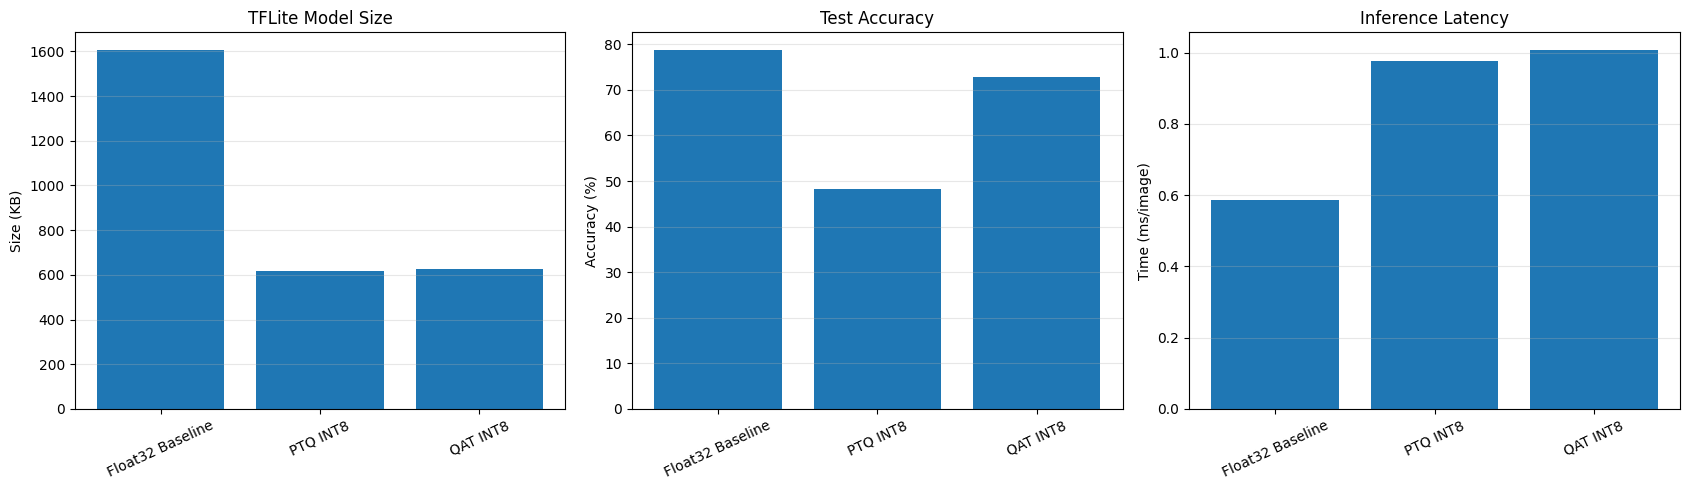

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Model size
axes[0].bar(
    comparison_df["Model"],
    comparison_df["Model Size (KB)"]
)
axes[0].set_title("TFLite Model Size")
axes[0].set_ylabel("Size (KB)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.3)

# Accuracy
axes[1].bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy (%)"]
)
axes[1].set_title("Test Accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.3)

# Latency
axes[2].bar(
    comparison_df["Model"],
    comparison_df["Latency (ms/image)"]
)
axes[2].set_title("Inference Latency")
axes[2].set_ylabel("Time (ms/image)")
axes[2].tick_params(axis="x", rotation=25)
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### **22: Save the results**

In [22]:
comparison_df.to_csv(
    "qat_ptq_comparison.csv",
    index=False
)

print("Comparison saved to qat_ptq_comparison.csv")

Comparison saved to qat_ptq_comparison.csv


### **Interpretation of Results**

Based on our comparison table, we can analyze the performance trade-offs between the three models across three dimensions:

1. **Model Size & Storage Efficiency:**
   * **Float32 Baseline:** Weighs in at approximately **1.6 MB**.
   * **PTQ & QAT INT8:** Both compressed models drop to approximately **620 KB**, representing a massive **~61% reduction in model size**.
   * *Takeaway:* Quantization successfully compacts the network, which is critical for edge deployment where storage and memory bandwidth are heavily constrained.

2. **Test Accuracy:**
   * **Float32 Baseline:** Achieves **78.70%** accuracy.
   * **PTQ INT8:** Drops significantly to **48.30%** accuracy. Post-Training Quantization causes severe quantization noise because weights are mapped statically without retraining.
   * **QAT INT8:** Recovers the drop remarkably, reaching **72.90%** accuracy (only a small 5.8% drop from baseline).
   * *Takeaway:* For complex datasets and architectures like MobileNetV2, **Quantization-Aware Training (QAT)** is essential to preserve classification accuracy during the quantization process.

3. **Inference Latency:**
   * On standard CPU execution without hardware-specific delegation (like Edge TPU or Android NNAPI), the integer execution overhead and emulation of INT8 arithmetic can result in slightly higher or comparable latencies (~1.0 ms vs 0.58 ms) compared to highly optimized floating-point routines. In a production edge device with a dedicated DSP/TPU accelerator, the INT8 models would execute significantly faster.